In [104]:
# Library

In [105]:
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis 
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import RidgeClassifier, SGDClassifier
from sklearn.svm import LinearSVC, SVC
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from function import *

In [106]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [107]:
data = pd.read_csv('data/alzheimer_dataset.csv')

In [108]:
data.isnull().sum()

directory.id               0
Subject                    0
RID                        0
Image.Data.ID              0
Modality                   0
Visit                      0
Acq.Date                   0
DX.bl                      0
EXAMDATE                   0
Age                        0
Gender                     0
Education_Year             0
Ethnicity                  0
Race                       0
APOE4_Status               0
MMSE                       0
Imputed_Genotype           0
APOE_Genotype              0
Dx Codes for Submission    0
dtype: int64

In [109]:
data = data.dropna()
data.isnull().sum().sum()

0

In [110]:
data.head(5)

,directory.id,Subject,RID,Image.Data.ID,Modality,Visit,Acq.Date,DX.bl,EXAMDATE,Age,Gender,Education_Year,Ethnicity,Race,APOE4_Status,MMSE,Imputed_Genotype,APOE_Genotype,Dx Codes for Submission
0,4702245ea294ce5d4e9b8a87027dfdf4,011_S_0003,3,32237,MRI,1,09-01-2005,AD,09-12-2005,81.3,Male,18,Not Hisp/Latino,White,1,20,True,"(3,4)",AD
1,2e89e352af743597b2368c412e0f6de2,022_S_0004,4,64631,MRI,1,9/22/05,LMCI,11-08-2005,67.5,Male,10,Hisp/Latino,White,0,27,False,"(3,3)",MCI
2,90419199306997753de8042f1fd55e38,011_S_0005,5,32246,MRI,1,09-02-2005,CN,09-07-2005,73.7,Male,16,Not Hisp/Latino,White,0,29,True,"(3,3)",CN
3,d8d175ffff1e2053e6a18c5df494ccdf,100_S_0006,6,33025,MRI,1,11/15/05,LMCI,11/29/05,80.4,Female,13,Not Hisp/Latino,White,0,25,True,"(3,3)",MCI
4,986e75b2e604cd44b38feb2188476fb2,011_S_0010,10,32270,MRI,1,11-07-2005,AD,11-10-2005,73.9,Female,12,Not Hisp/Latino,White,1,24,True,"(3,4)",AD


In [111]:
X = data
Y = data['DX.bl']
# del data

remove_columns = list(X.columns)[0:9]
remove_columns.append('Dx Codes for Submission')
print('Removing columns:', remove_columns)

X = X.drop(remove_columns, axis=1)

features = list(X.columns)
X.head(5)p

Removing columns: ['directory.id', 'Subject', 'RID', 'Image.Data.ID', 'Modality', 'Visit', 'Acq.Date', 'DX.bl', 'EXAMDATE', 'Dx Codes for Submission']


,Age,Gender,Education_Year,Ethnicity,Race,APOE4_Status,MMSE,Imputed_Genotype,APOE_Genotype
0,81.3,Male,18,Not Hisp/Latino,White,1,20,True,"(3,4)"
1,67.5,Male,10,Hisp/Latino,White,0,27,False,"(3,3)"
2,73.7,Male,16,Not Hisp/Latino,White,0,29,True,"(3,3)"
3,80.4,Female,13,Not Hisp/Latino,White,0,25,True,"(3,3)"
4,73.9,Female,12,Not Hisp/Latino,White,1,24,True,"(3,4)"


In [112]:
#Exploratory Data Analysis

Number of data points per class:
DX.bl
LMCI    304
CN      190
AD      133
Name: count, dtype: int64


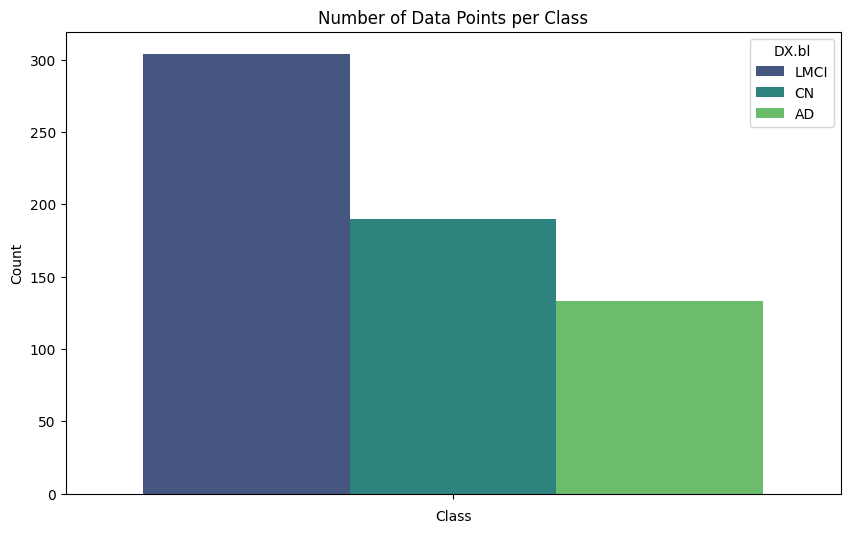

In [113]:
# Show the number of data points per class
class_counts = Y.value_counts()
print("Number of data points per class:")
print(class_counts)

# Plot the number of data points per class
plt.figure(figsize=(10, 6))
sns.barplot(hue=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Number of Data Points per Class')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

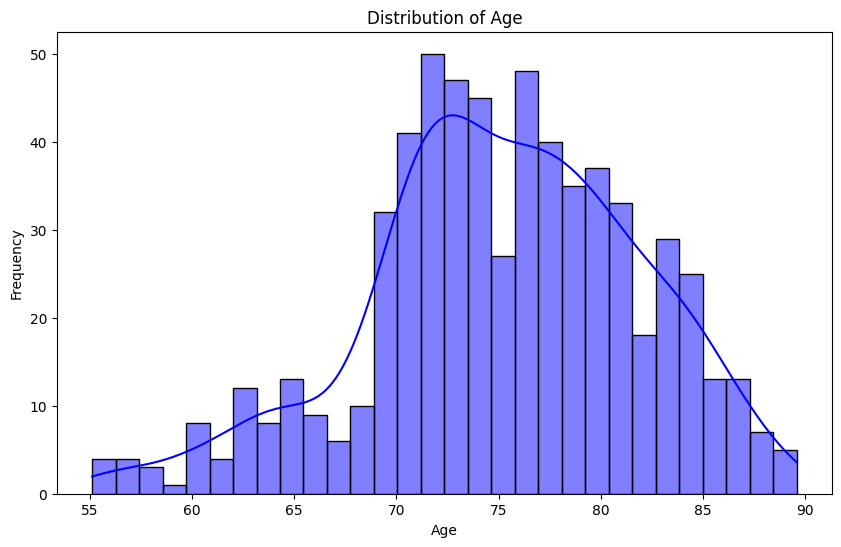

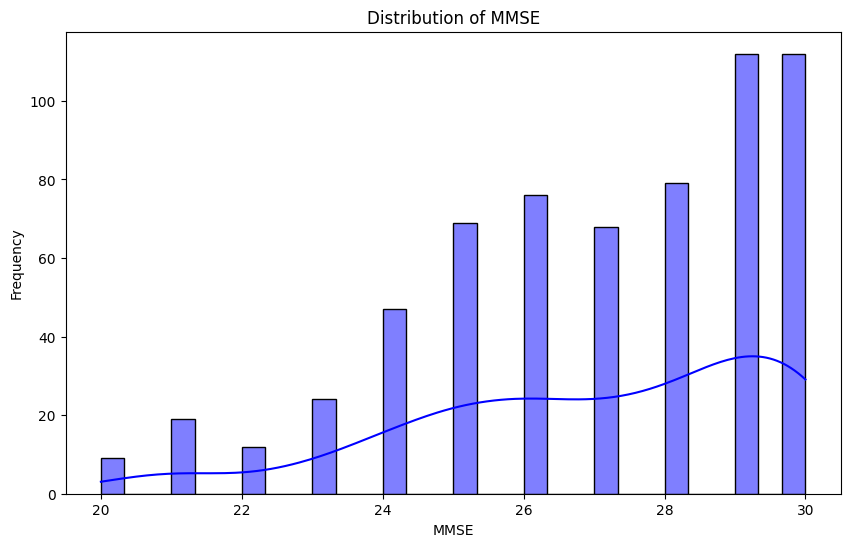

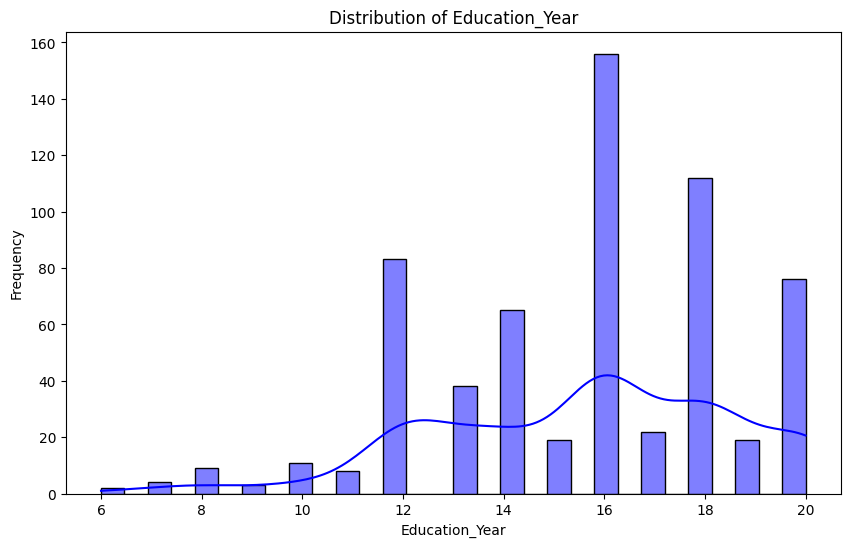

In [114]:
# Distribution of Numerical Features
numerical_vars = ['Age', 'MMSE', 'Education_Year']
for var in numerical_vars:
    plt.figure(figsize=(10, 6))
    sns.histplot(data[var], kde=True, bins=30, color='blue')
    plt.title(f'Distribution of {var}')
    plt.xlabel(var)
    plt.ylabel('Frequency')
    plt.show()

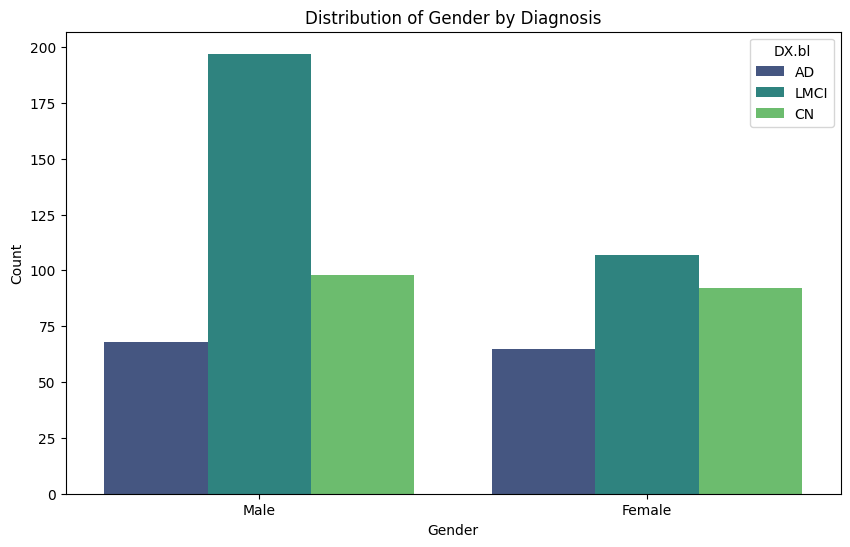

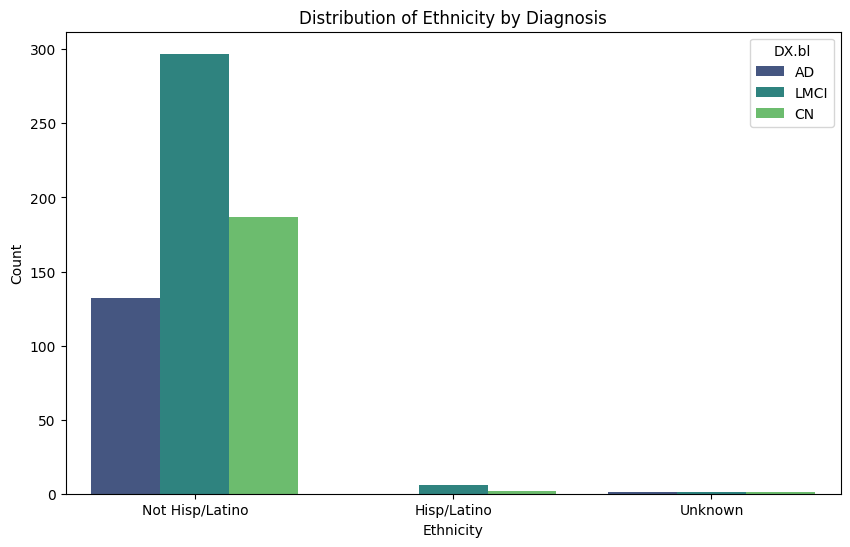

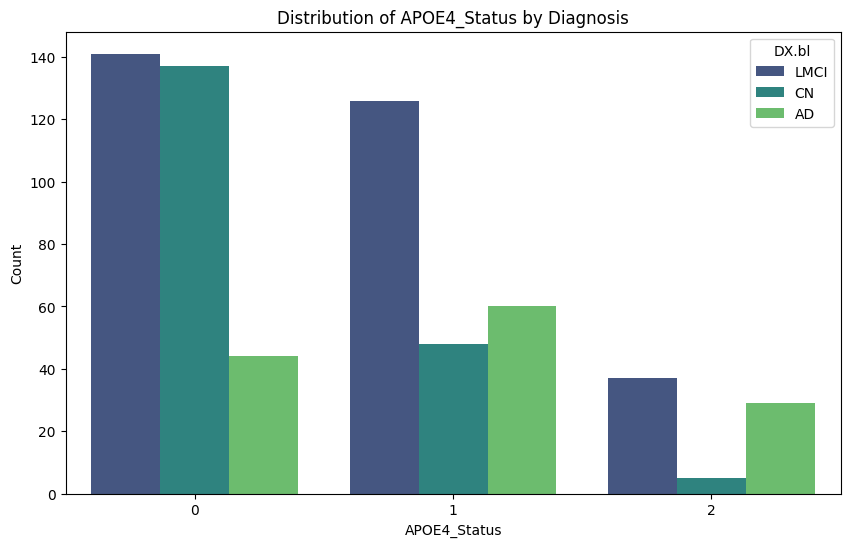

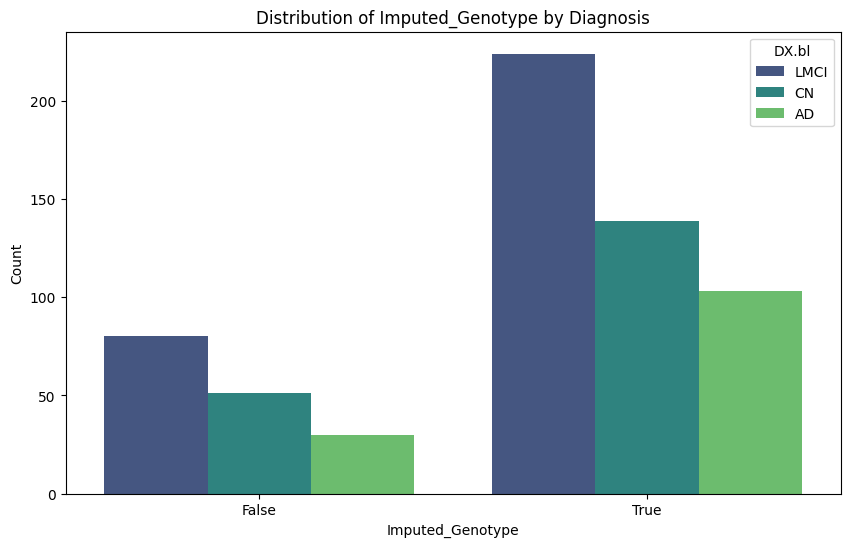

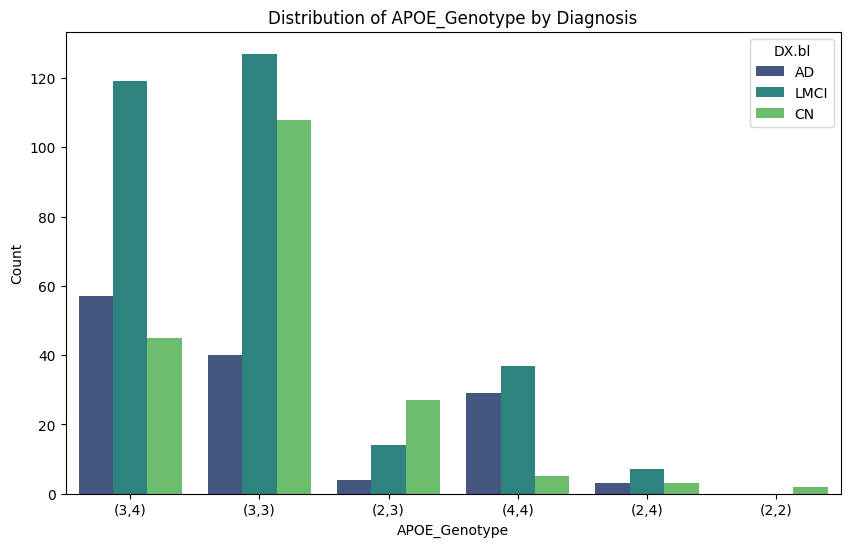

In [115]:
# Categorical Feature Distributions
categorical_vars = ['Gender', 'Ethnicity', 'APOE4_Status', 'Imputed_Genotype', 'APOE_Genotype']
for var in categorical_vars:
    plt.figure(figsize=(10, 6))
    sns.countplot(x=var, hue='DX.bl', data=data, palette='viridis')
    plt.title(f'Distribution of {var} by Diagnosis')
    plt.xlabel(var)
    plt.ylabel('Count')
    plt.show()

In [116]:
gender_ethnicity_counts = data.groupby(['DX.bl', 'Gender', 'Ethnicity']).size().reset_index(name='count')
print(gender_ethnicity_counts)

   DX.bl  Gender        Ethnicity  count
0     AD  Female  Not Hisp/Latino     64
1     AD  Female          Unknown      1
2     AD    Male  Not Hisp/Latino     68
3     CN  Female      Hisp/Latino      2
4     CN  Female  Not Hisp/Latino     89
5     CN  Female          Unknown      1
6     CN    Male  Not Hisp/Latino     98
7   LMCI  Female      Hisp/Latino      4
8   LMCI  Female  Not Hisp/Latino    102
9   LMCI  Female          Unknown      1
10  LMCI    Male      Hisp/Latino      2
11  LMCI    Male  Not Hisp/Latino    195


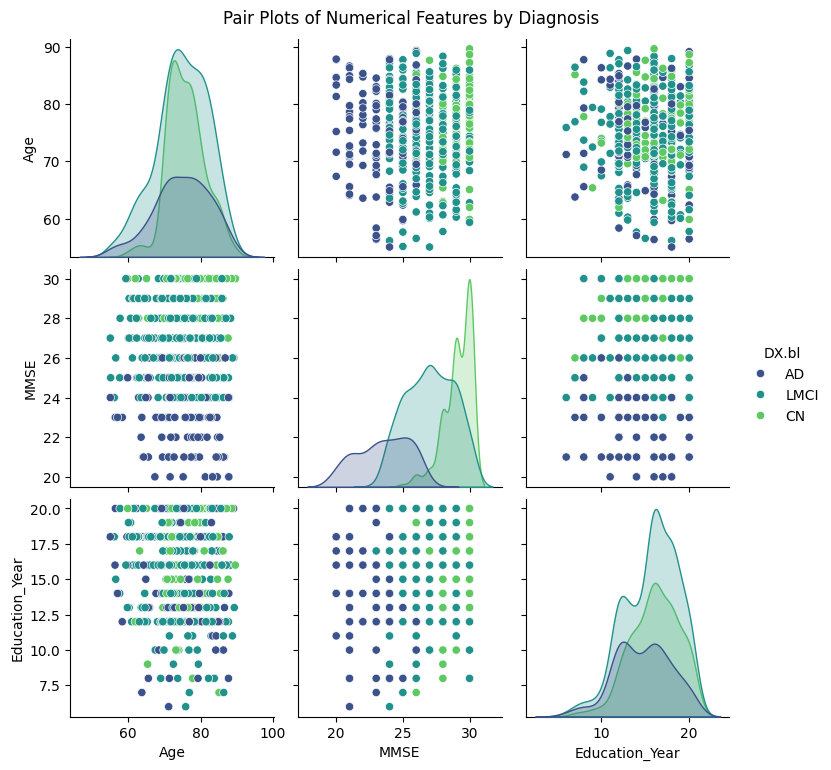

In [117]:
# Pair Plots
sns.pairplot(data, hue='DX.bl', vars=numerical_vars, palette='viridis')
plt.suptitle('Pair Plots of Numerical Features by Diagnosis', y=1.02)
plt.show()

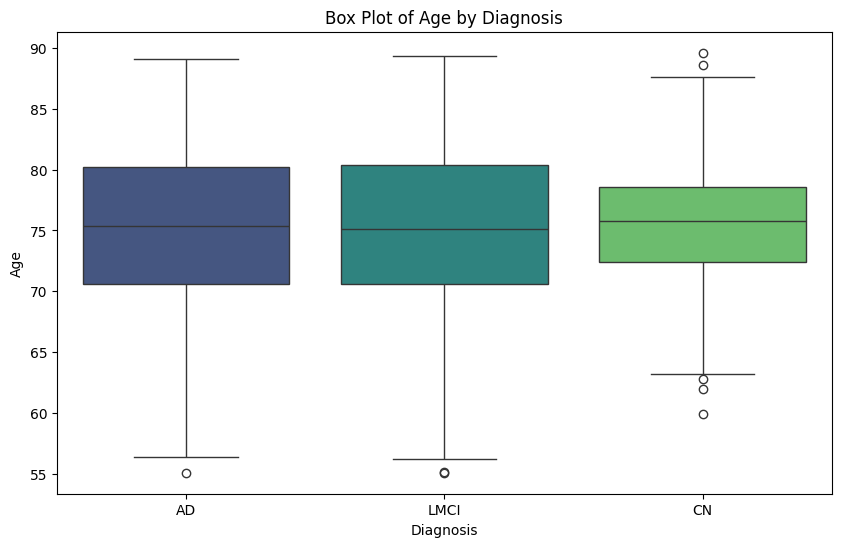

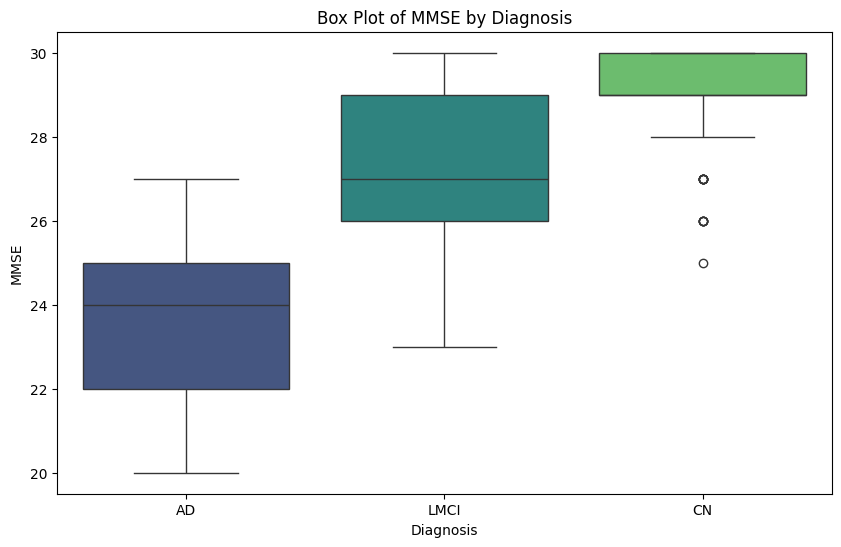

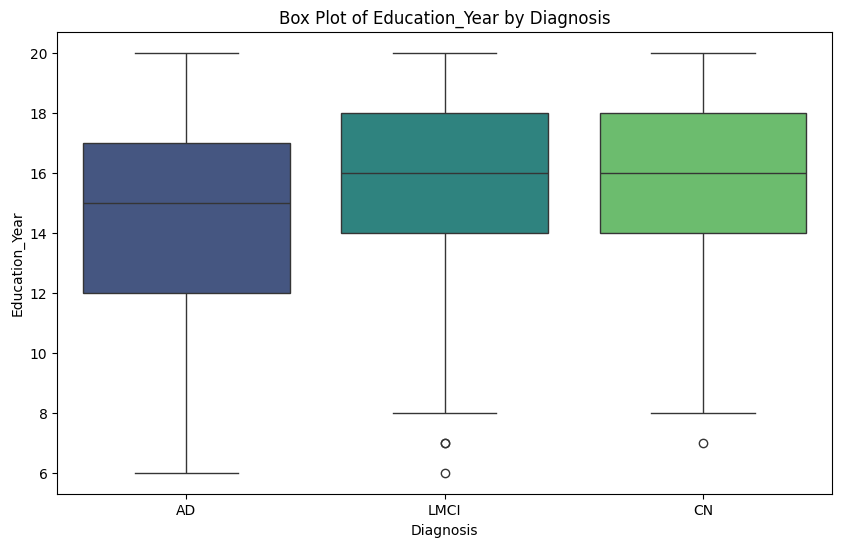

In [118]:
# Box Plots
for var in numerical_vars:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='DX.bl', y=var, data=data, palette='viridis')
    plt.title(f'Box Plot of {var} by Diagnosis')
    plt.xlabel('Diagnosis')
    plt.ylabel(var)
    plt.show()

In [119]:
numerical_vars = ['Age', 'MMSE', 'Education_Year']
cat_vars = list(set(features) - set(numerical_vars))

print('Categorical variable distributions:\n')

for var in cat_vars:
    print('\nDistribution of', var)
    
    print(X[var].value_counts())

Categorical variable distributions:


Distribution of Race
Race
White    583
Black     31
Asian     13
Name: count, dtype: int64

Distribution of Gender
Gender
Male      363
Female    264
Name: count, dtype: int64

Distribution of Imputed_Genotype
Imputed_Genotype
True     466
False    161
Name: count, dtype: int64

Distribution of APOE4_Status
APOE4_Status
0    322
1    234
2     71
Name: count, dtype: int64

Distribution of Ethnicity
Ethnicity
Not Hisp/Latino    616
Hisp/Latino          8
Unknown              3
Name: count, dtype: int64

Distribution of APOE_Genotype
APOE_Genotype
(3,3)    275
(3,4)    221
(4,4)     71
(2,3)     45
(2,4)     13
(2,2)      2
Name: count, dtype: int64


In [120]:
for var in cat_vars:
    print(f'Converting {var} to 1-hot encoding')
    one_hot_df = pd.get_dummies(X[var], prefix=var)
    X = pd.concat([X, one_hot_df], axis=1)
    X.drop(var, axis=1, inplace=True)
    
X.head(4)

Converting Race to 1-hot encoding
Converting Gender to 1-hot encoding
Converting Imputed_Genotype to 1-hot encoding
Converting APOE4_Status to 1-hot encoding
Converting Ethnicity to 1-hot encoding
Converting APOE_Genotype to 1-hot encoding


,Age,Education_Year,MMSE,Race_Asian,Race_Black,Race_White,Gender_Female,Gender_Male,Imputed_Genotype_False,Imputed_Genotype_True,...,APOE4_Status_2,Ethnicity_Hisp/Latino,Ethnicity_Not Hisp/Latino,Ethnicity_Unknown,"APOE_Genotype_(2,2)","APOE_Genotype_(2,3)","APOE_Genotype_(2,4)","APOE_Genotype_(3,3)","APOE_Genotype_(3,4)","APOE_Genotype_(4,4)"
0,81.3,18,20,False,False,True,False,True,False,True,...,False,False,True,False,False,False,False,False,True,False
1,67.5,10,27,False,False,True,False,True,True,False,...,False,True,False,False,False,False,False,True,False,False
2,73.7,16,29,False,False,True,False,True,False,True,...,False,False,True,False,False,False,False,True,False,False
3,80.4,13,25,False,False,True,True,False,False,True,...,False,False,True,False,False,False,False,True,False,False


In [121]:
# Data Preprocessing

In [122]:
# perform data balancing and train test split

In [123]:
# Apply SMOTE to balance the training set
smote = SMOTE(random_state=42)
X_balanced, y_balanced = smote.fit_resample(X, Y)


In [124]:
# Apply SMOTE to balance the training set
X_train_balanced, X_test_balanced, y_train_balanced, y_test_balanced = train_test_split(X_balanced, y_balanced, test_size=.2)
num_test = X_test_balanced.shape[0]


Number of data points per class:
DX.bl
CN      249
LMCI    247
AD      233
Name: count, dtype: int64


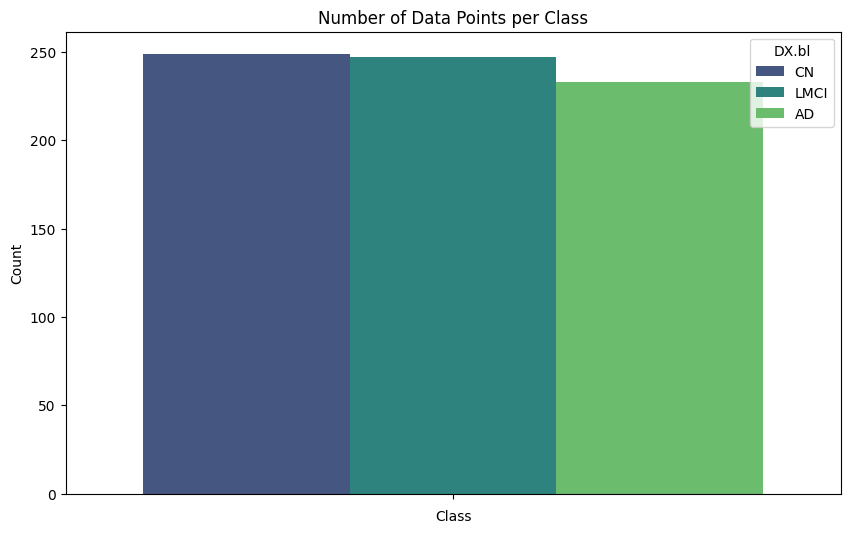

In [125]:
# Show the number of data points per class
class_counts = y_train_balanced.value_counts()
print("Number of data points per class:")
print(class_counts)

# Plot the number of data points per class
plt.figure(figsize=(10, 6))
sns.barplot(hue=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Number of Data Points per Class')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [126]:
X_train_balanced.columns = X_train_balanced.columns.astype(str)
X_test_balanced.columns = X_test_balanced.columns.astype(str)

In [127]:
# # Train a Linear Discriminant Analysis model
# lda_clf = LinearDiscriminantAnalysis(solver='svd', store_covariance=False, tol=0.0001)
# lda_clf.fit(X_train_balanced, y_train_balanced)

# y_pred = lda_clf.predict(X_test_balanced)

# print('Cross Validation:', format(cross_val_score(lda_clf, X_train_balanced, y_train_balanced, cv=5).mean(), '.2%'))
# print('Accuracy:', format(accuracy_score(y_test_balanced, y_pred), '.2%'))
# print('Precision:', format(precision_score(y_test_balanced, y_pred, average='weighted'), '.2%'))
# print('Recall:', format(recall_score(y_test_balanced, y_pred, average='weighted'), '.2%'))
# print('F1 Score:', format(f1_score(y_test_balanced, y_pred, average='weighted'), '.2%'))

# # Confusion Matrix
# conf_matrix = confusion_matrix(y_test_balanced, y_pred)

# # Get the class labels
# class_names = y_test_balanced.unique()

# # Plot the heatmap with class labels
# plt.figure(figsize=(10, 7))
# sns.heatmap(conf_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=class_names, yticklabels=class_names)
# plt.xlabel('Predicted Labels')
# plt.ylabel('True Labels')
# plt.title('Confusion Matrix with Class Labels')
# plt.show()

In [128]:
lda_clf = LinearDiscriminantAnalysis(solver='svd', store_covariance=False, tol=0.0001)
lda_clf = lda_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Linear Discriminant Analysis Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.90      0.76      0.82        71
        LMCI       0.67      0.69      0.68        55
          CN       0.50      0.58      0.54        57

    accuracy                           0.68       183
   macro avg       0.69      0.68      0.68       183
weighted avg       0.71      0.68      0.69       183

__________________________________________________________________


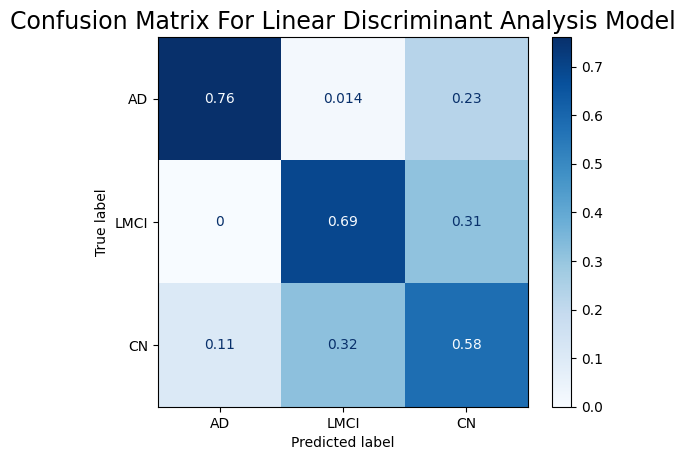

__________________________________________________________________


In [129]:
evaluate_model(lda_clf, X_train_balanced, X_test_balanced, y_test_balanced, title='Linear Discriminant Analysis Model')

In [131]:
log_clf = LogisticRegressionCV(solver='lbfgs', 
                               class_weight='balanced',
                               max_iter=1000000,
                               penalty='l2',
                               l1_ratios=[.1,.3,.5,.7,.9],
                               multi_class='multinomial',
                               random_state=123, 
                               n_jobs=-1, cv=5)

log_base = log_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Logistic Regression Base Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.92      0.79      0.85        71
        LMCI       0.72      0.69      0.70        55
          CN       0.54      0.65      0.59        57

    accuracy                           0.72       183
   macro avg       0.72      0.71      0.71       183
weighted avg       0.74      0.72      0.72       183

__________________________________________________________________


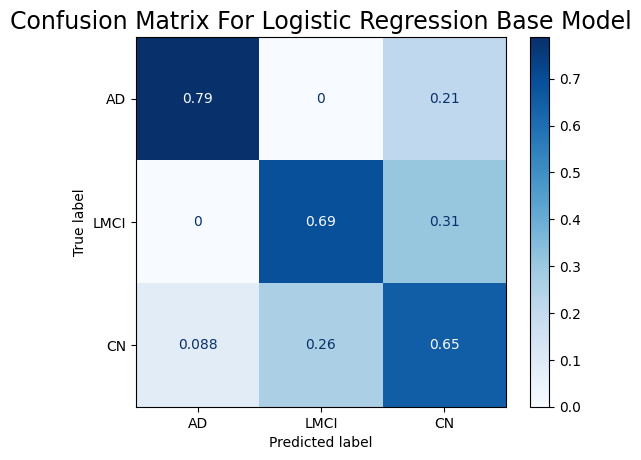

__________________________________________________________________


In [132]:
evaluate_model(log_base,X_train_balanced,X_test_balanced,y_test_balanced,title='Logistic Regression Base Model')

In [133]:
# Hyperparameter Tuning

Best parameters: {'Cs': 100, 'class_weight': 'balanced', 'cv': 10, 'max_iter': 1000000, 'multi_class': 'multinomial', 'penalty': 'l2', 'solver': 'lbfgs'}
Best accuracy: 0.790118091639112
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tuned Logistic Regression Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.89      0.76      0.82        71
        LMCI       0.70      0.67      0.69        55
          CN       0.52      0.63      0.57        57

    accuracy                           0.69       183
   macro avg       0.70      0.69      0.69       183
weighted avg       0.72      0.69      0.70       183

__________________________________________________________________


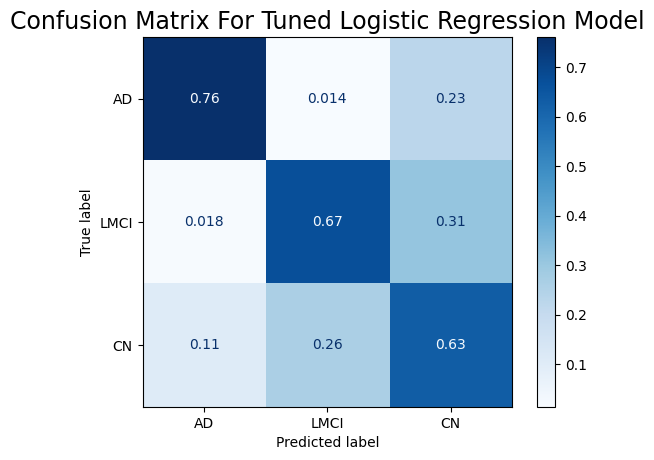

__________________________________________________________________


In [134]:
# Define the parameter grid
param_grid = {
    'Cs': [1, 10, 100],
    'cv': [5, 10],
    'solver': ['lbfgs'],
    'max_iter': [1000000],
    'penalty': ['l2'],
    'multi_class': ['multinomial'],
    'class_weight': ['balanced']
}

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=LogisticRegressionCV(random_state=123, n_jobs=-1),
                           param_grid=param_grid, scoring='accuracy', cv=5, n_jobs=-1, verbose=0)

# Fit the grid search to your data
grid_search.fit(X_train_balanced, y_train_balanced)

# Print the best parameters and best score
print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_)

# Evaluate the best model on the test set
best_log_clf = grid_search.best_estimator_
evaluate_model(best_log_clf, X_train_balanced, X_test_balanced, y_test_balanced, title='Tuned Logistic Regression Model')


In [135]:
rf_clf = RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                                criterion='gini', max_depth=None, max_features='sqrt',
                                max_leaf_nodes=None, max_samples=None,
                                min_impurity_decrease=0.0, min_samples_leaf=1,
                                min_samples_split=2, min_weight_fraction_leaf=0.0,
                                n_estimators=100, n_jobs=-1, oob_score=False,
                                random_state=123, verbose=0, warm_start=False)

rf_clf = rf_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Random Forest Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.82      0.83      0.83        71
        LMCI       0.75      0.69      0.72        55
          CN       0.53      0.56      0.55        57

    accuracy                           0.70       183
   macro avg       0.70      0.69      0.70       183
weighted avg       0.71      0.70      0.71       183

__________________________________________________________________


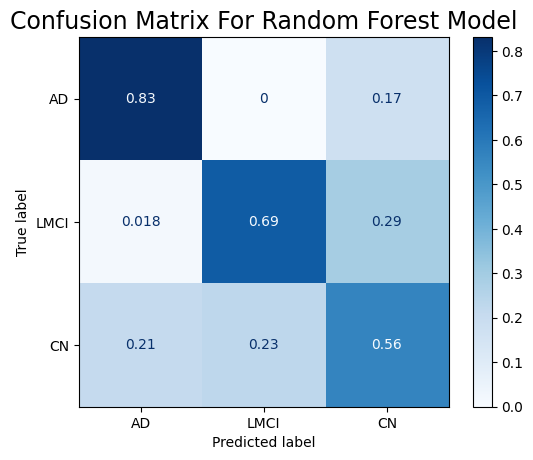

__________________________________________________________________


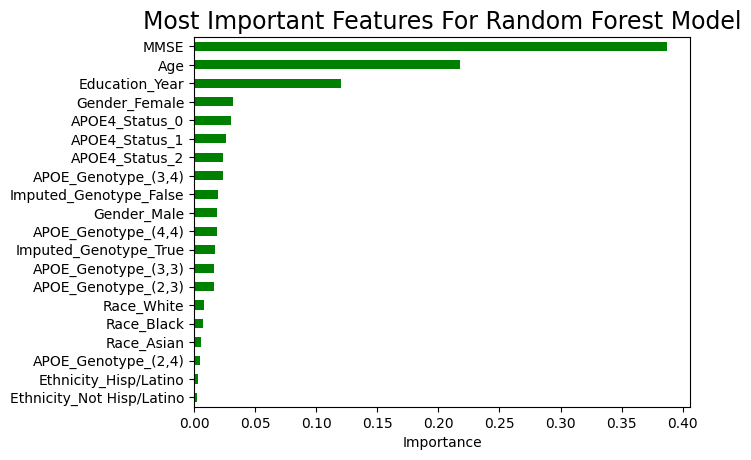

In [136]:
evaluate_model(rf_clf, X_train_balanced, X_test_balanced, y_test_balanced, tree=True ,title='Random Forest Model')

Best parameters: {'bootstrap': True, 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best accuracy: 0.8010973936899862
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tuned Random Forest Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.78      0.82      0.80        71
        LMCI       0.76      0.76      0.76        55
          CN       0.54      0.51      0.52        57

    accuracy                           0.70       183
   macro avg       0.69      0.70      0.70       183
weighted avg       0.70      0.70      0.70       183

__________________________________________________________________


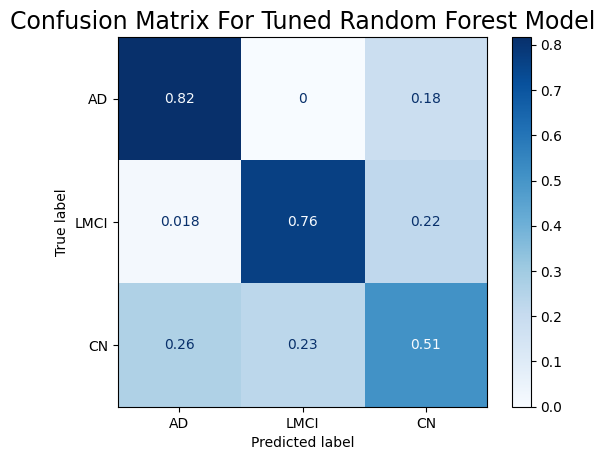

__________________________________________________________________


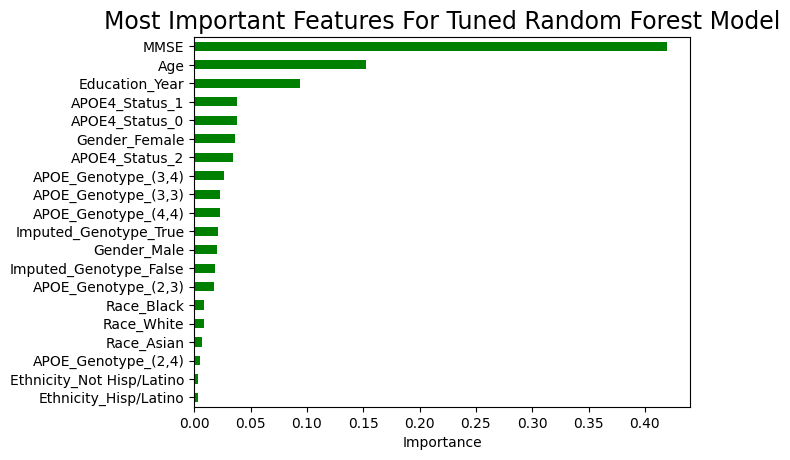

In [137]:
# Define the Random Forest Classifier
rf_clf = RandomForestClassifier(random_state=123, n_jobs=-1)

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_features': ['auto', 'sqrt', 'log2'],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=rf_clf, param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1, verbose=0)

# Fit the grid search to your data

grid_search.fit(X_train_balanced, y_train_balanced)

# Print the best parameters and best score
print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_)

# Evaluate the best model on the test set
best_rf_clf = grid_search.best_estimator_
evaluate_model(best_rf_clf, X_train_balanced, X_test_balanced, y_test_balanced, tree=True, title='Tuned Random Forest Model')


In [138]:
rg_clf = RidgeClassifier(alpha=1.0, copy_X=True, fit_intercept=True, random_state=123, solver='auto', tol=0.0001)

rg_clf = rg_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Ridge Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.81      0.85      0.83        71
        LMCI       0.68      0.71      0.70        55
          CN       0.48      0.44      0.46        57

    accuracy                           0.68       183
   macro avg       0.66      0.66      0.66       183
weighted avg       0.67      0.68      0.67       183

__________________________________________________________________


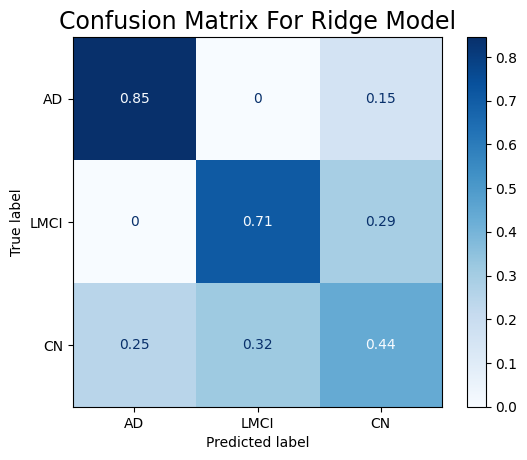

__________________________________________________________________


In [139]:
evaluate_model(rg_clf, X_train_balanced, X_test_balanced, y_test_balanced, title='Ridge Model')

Best parameters: {'alpha': 10.0, 'tol': 0.0001}
Best accuracy: 0.7626886145404663
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tuned Ridge Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.81      0.86      0.84        71
        LMCI       0.67      0.75      0.71        55
          CN       0.49      0.40      0.44        57

    accuracy                           0.68       183
   macro avg       0.66      0.67      0.66       183
weighted avg       0.67      0.68      0.67       183

__________________________________________________________________


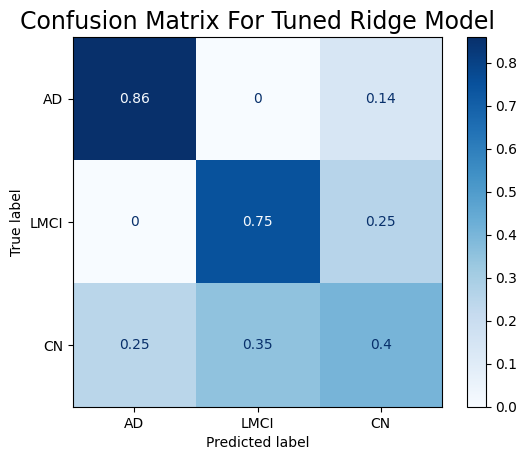

__________________________________________________________________


In [140]:

# Define the Ridge Classifier
rg_clf = RidgeClassifier(random_state=123)

# Define the hyperparameter grid
param_grid = {
    'alpha': [0.1, 1.0, 10.0],
    'tol': [1e-4, 1e-3, 1e-2],
}

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=rg_clf, param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1, verbose=0)

# Fit the grid search to your data
grid_search.fit(X_train_balanced, y_train_balanced)

# Print the best parameters and best score
print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_)

# Evaluate the best model on the test set
best_rg_clf = grid_search.best_estimator_
evaluate_model(best_rg_clf, X_train_balanced, X_test_balanced, y_test_balanced, title='Tuned Ridge Model')


In [141]:
gb_clf = GradientBoostingClassifier(ccp_alpha=0.0, criterion='friedman_mse', init=None,
                            learning_rate=0.1, loss='log_loss', max_depth=3,
                            max_features=None, max_leaf_nodes=None,
                            min_impurity_decrease=0.0, min_samples_leaf=1,
                            min_samples_split=2, min_weight_fraction_leaf=0.0,
                            n_estimators=100, n_iter_no_change=None,
                            random_state=123, subsample=1.0, tol=0.0001,
                            validation_fraction=0.1, verbose=0,
                            warm_start=False)

gb_clf = gb_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Gradient Boosting Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.86      0.77      0.81        71
        LMCI       0.75      0.75      0.75        55
          CN       0.55      0.61      0.58        57

    accuracy                           0.72       183
   macro avg       0.72      0.71      0.71       183
weighted avg       0.73      0.72      0.72       183

__________________________________________________________________


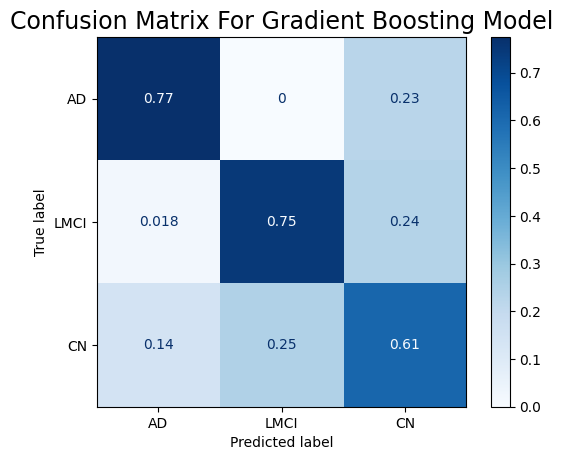

__________________________________________________________________


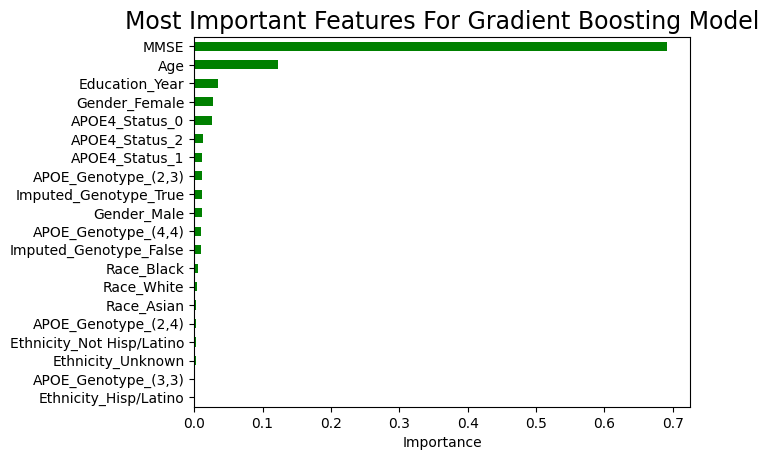

In [142]:
evaluate_model(gb_clf, X_train_balanced, X_test_balanced, y_test_balanced, tree=True ,title='Gradient Boosting Model')

Best parameters: {'learning_rate': 0.05, 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best accuracy: 0.7928669410150891
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tuned Gradient Boosting Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.84      0.83      0.84        71
        LMCI       0.72      0.69      0.70        55
          CN       0.53      0.56      0.55        57

    accuracy                           0.70       183
   macro avg       0.70      0.69      0.70       183
weighted avg       0.71      0.70      0.71       183

__________________________________________________________________


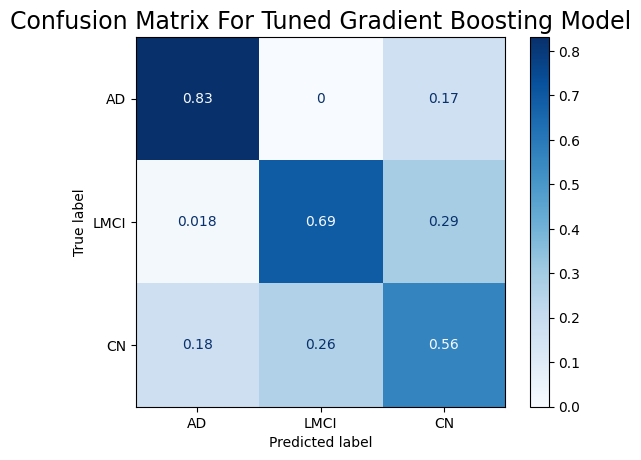

__________________________________________________________________


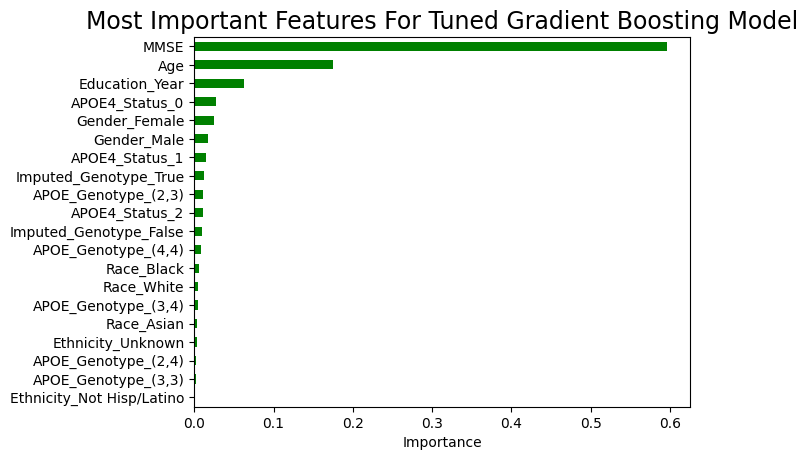

In [143]:
# Define the Gradient Boosting Classifier
gb_clf = GradientBoostingClassifier(random_state=123)

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=gb_clf, param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1, verbose=0)

# Fit the grid search to your data
grid_search.fit(X_train_balanced, y_train_balanced)

# Print the best parameters and best score
print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_)

# Evaluate the best model on the test set
best_gb_clf = grid_search.best_estimator_
evaluate_model(best_gb_clf, X_train_balanced, X_test_balanced, y_test_balanced, tree=True, title='Tuned Gradient Boosting Model')

In [144]:
mlp_clf = MLPClassifier(hidden_layer_sizes=(15, 10), alpha=3, learning_rate='adaptive', max_iter=100000)

mlp_clf = mlp_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	MLP Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.90      0.80      0.85        71
        LMCI       0.67      0.71      0.69        55
          CN       0.53      0.58      0.55        57

    accuracy                           0.70       183
   macro avg       0.70      0.70      0.70       183
weighted avg       0.72      0.70      0.71       183

__________________________________________________________________


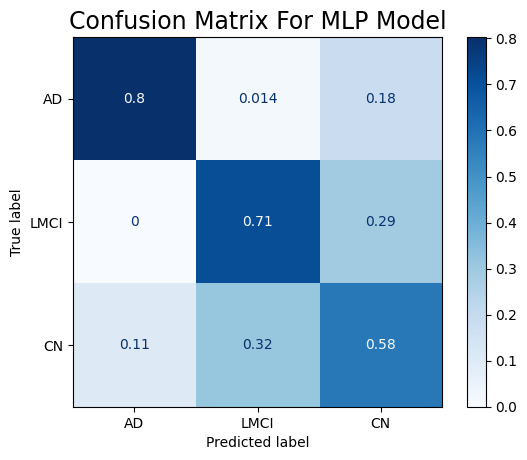

__________________________________________________________________


In [145]:
evaluate_model(mlp_clf, X_train_balanced, X_test_balanced, y_test_balanced, title='MLP Model')

Best parameters: {'alpha': 0.1, 'hidden_layer_sizes': (100,), 'learning_rate': 'constant', 'solver': 'adam'}
Best accuracy: 0.7325102880658436
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tuned MLP Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.84      0.80      0.82        71
        LMCI       0.65      0.62      0.64        55
          CN       0.54      0.60      0.57        57

    accuracy                           0.68       183
   macro avg       0.68      0.67      0.67       183
weighted avg       0.69      0.68      0.69       183

__________________________________________________________________


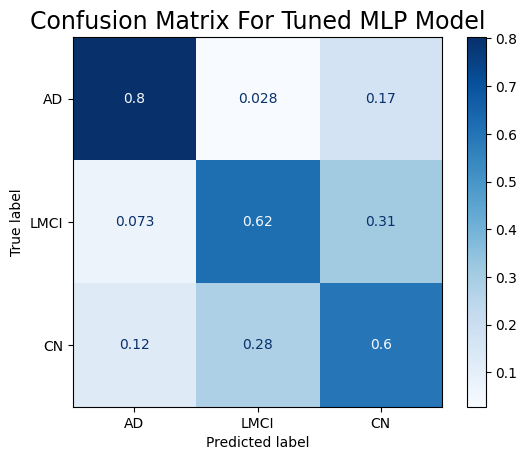

__________________________________________________________________


In [146]:
# Define the MLP Classifier
mlp_clf = MLPClassifier(max_iter=100000, random_state=123)

# Define the hyperparameter grid
param_grid = {
    'hidden_layer_sizes': [(10,), (50,), (100,), (15, 10), (50, 25)],
    'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 3],
    'learning_rate': ['constant', 'invscaling', 'adaptive'],
    'solver': ['adam', 'sgd']
}

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=mlp_clf, param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1, verbose=0)

# Fit the grid search to your data
grid_search.fit(X_train_balanced, y_train_balanced)

# Print the best parameters and best score
print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_)

# Evaluate the best model on the test set
best_mlp_clf = grid_search.best_estimator_

evaluate_model(best_mlp_clf, X_train_balanced, X_test_balanced, y_test_balanced, title='Tuned MLP Model')


In [147]:
# Calculate class weight and turn into a dictionary
from sklearn.utils import class_weight
k_train = class_weight.compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
wt = dict(zip(np.unique(y_train_balanced), k_train))

# Map class weights to y_train values
w_array = y_train_balanced.map(wt)
set(zip(y_train_balanced, w_array))
w_array = w_array.values

In [148]:
# Encode the labels
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_balanced)
y_test_encoded = label_encoder.transform(y_test_balanced)

In [149]:
xgb_clf = XGBClassifier(n_jobs=-1,
                        random_state=123,
                        # use_label_encoder=False,
                        eval_metric='mlogloss')

xgb_clf = xgb_clf.fit(X_train_balanced, y_train_encoded, sample_weight=w_array)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	XGBoost Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.85      0.85      0.85        71
        LMCI       0.73      0.73      0.73        55
          CN       0.56      0.56      0.56        57

    accuracy                           0.72       183
   macro avg       0.71      0.71      0.71       183
weighted avg       0.72      0.72      0.72       183

__________________________________________________________________


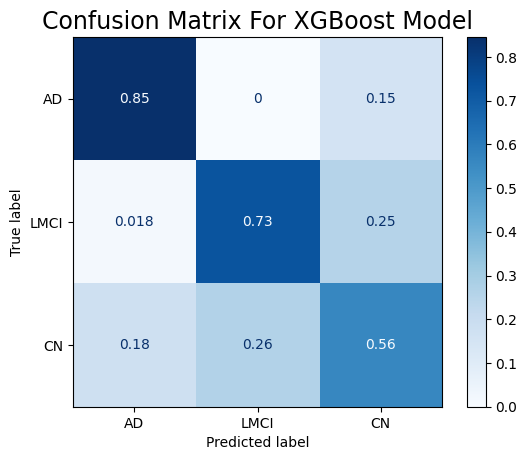

__________________________________________________________________


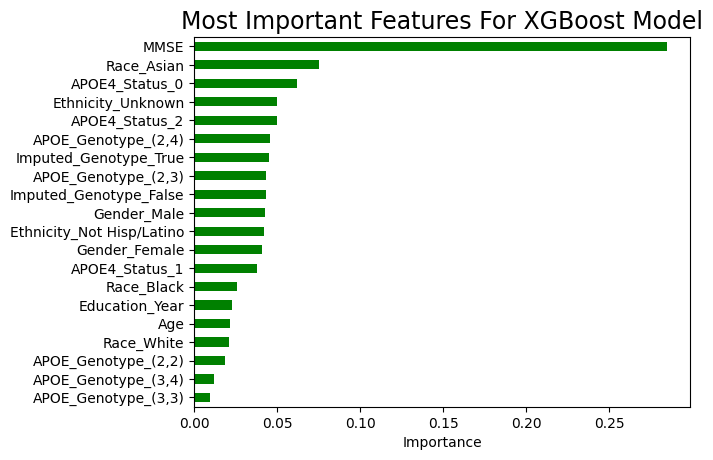

In [151]:
evaluate_model(xgb_clf, X_train_balanced, X_test_balanced, y_test_encoded, tree=True ,title='XGBoost Model')

Best Parameters:  {'colsample_bytree': 0.9, 'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 50, 'subsample': 0.9}
Best Estimator:  XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=50,
              n_jobs=-1, num_parallel_tree=None, objective='multi:softprob', ...)
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tun

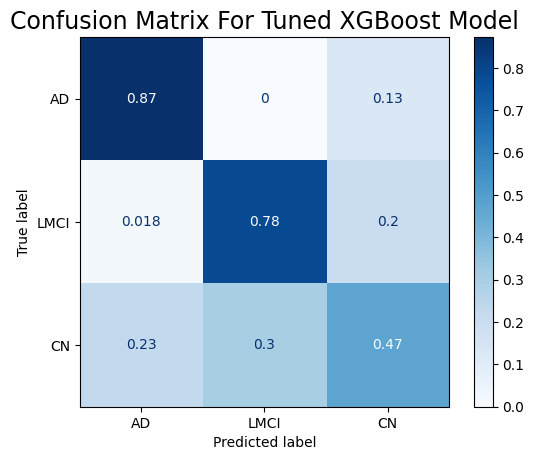

__________________________________________________________________


In [152]:
# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

# Create the XGBoost classifier
xgb_clf = XGBClassifier(n_jobs=-1, random_state=123, eval_metric='mlogloss')

# Perform grid search
grid_search = GridSearchCV(estimator=xgb_clf, param_grid=param_grid, scoring='accuracy', n_jobs=-1, cv=5)
grid_search.fit(X_train_balanced, y_train_encoded, sample_weight=w_array)

# Best parameters and estimator
best_params = grid_search.best_params_
best_estimator = grid_search.best_estimator_

print("Best Parameters: ", best_params)
print("Best Estimator: ", best_estimator)

# Evaluate model using custom evaluation function
evaluate_model(best_estimator, X_train_balanced, X_test_balanced, y_test_encoded, title='Tuned XGBoost Model')

In [153]:
svm_clf = LinearSVC(random_state=123,
                    dual=False,
                    class_weight='balanced')

svm_clf = svm_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Linear SVM Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.87      0.82      0.84        71
        LMCI       0.66      0.67      0.67        55
          CN       0.50      0.53      0.51        57

    accuracy                           0.68       183
   macro avg       0.68      0.67      0.67       183
weighted avg       0.69      0.68      0.69       183

__________________________________________________________________


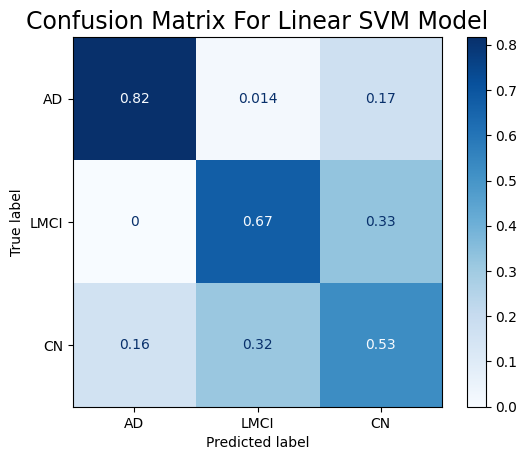

__________________________________________________________________


In [154]:
evaluate_model(svm_clf, X_train_balanced, X_test_balanced, y_test_balanced, title='Linear SVM Model')

Best Parameters:  {'C': 100}
Best Estimator:  LinearSVC(C=100, class_weight='balanced', dual=False, random_state=123)
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tuned Linear SVM Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.84      0.83      0.84        71
        LMCI       0.68      0.65      0.67        55
          CN       0.50      0.53      0.51        57

    accuracy                           0.68       183
   macro avg       0.67      0.67      0.67       183
weighted avg       0.69      0.68      0.68       183

__________________________________________________________________


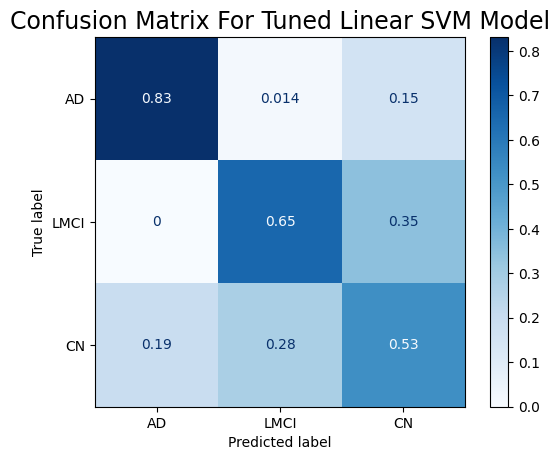

__________________________________________________________________


In [155]:
# Define the parameter grid
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100]
}

# Create the Linear SVM classifier
svm_clf = LinearSVC(random_state=123, dual=False, class_weight='balanced')

# Perform grid search
grid_search = GridSearchCV(estimator=svm_clf, param_grid=param_grid, scoring='accuracy', n_jobs=-1, cv=5)
grid_search.fit(X_train_balanced, y_train_balanced)

# Best parameters and estimator
best_params = grid_search.best_params_
best_estimator = grid_search.best_estimator_

print("Best Parameters: ", best_params)
print("Best Estimator: ", best_estimator)


# Evaluate the tuned model
evaluate_model(best_estimator, X_train_balanced, X_test_balanced, y_test_balanced, title='Tuned Linear SVM Model')


In [156]:
psvm_clf = SVC(random_state=123,
               kernel='poly',
               class_weight='balanced')

psvm_clf = psvm_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Polynomial SVM Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.80      0.79      0.79        71
        LMCI       0.67      0.82      0.74        55
          CN       0.50      0.40      0.45        57

    accuracy                           0.68       183
   macro avg       0.66      0.67      0.66       183
weighted avg       0.67      0.68      0.67       183

__________________________________________________________________


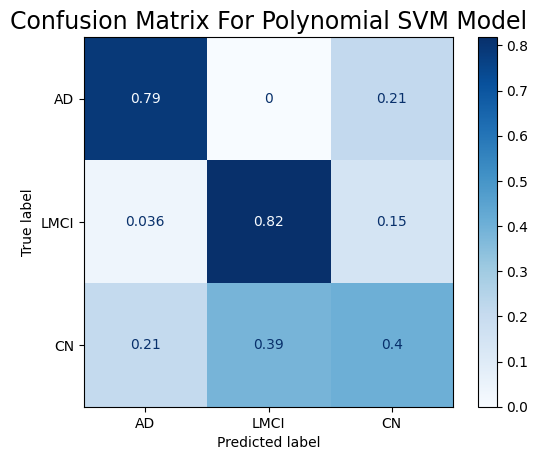

__________________________________________________________________


In [157]:
evaluate_model(psvm_clf, X_train_balanced, X_test_balanced, y_test_balanced, title='Polynomial SVM Model')

Best Parameters:  {'C': 10, 'coef0': 10, 'degree': 5}
Best Estimator:  SVC(C=10, class_weight='balanced', coef0=10, degree=5, kernel='poly',
    random_state=123)
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tuned Polynomial SVM Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.84      0.72      0.77        71
        LMCI       0.70      0.60      0.65        55
          CN       0.48      0.63      0.55        57

    accuracy                           0.66       183
   macro avg       0.67      0.65      0.66       183
weighted avg       0.68      0.66      0.66       183

__________________________________________________________________


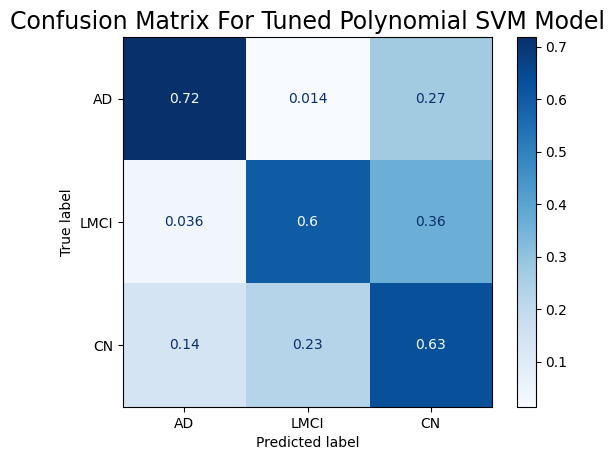

__________________________________________________________________


In [158]:
# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'degree': [2, 3, 4, 5],
    'coef0': [0, 1, 10]
} 

# Create the Polynomial SVM classifier
psvm_clf = SVC(kernel='poly', class_weight='balanced', random_state=123)

# Perform grid search
grid_search = GridSearchCV(estimator=psvm_clf, param_grid=param_grid, scoring='accuracy', n_jobs=-1, cv=5)
grid_search.fit(X_train_balanced, y_train_balanced)

# Best parameters and estimator
best_params = grid_search.best_params_
best_estimator = grid_search.best_estimator_

print("Best Parameters: ", best_params)
print("Best Estimator: ", best_estimator)

# Evaluate the tuned model
evaluate_model(best_estimator, X_train_balanced, X_test_balanced, y_test_balanced, title='Tuned Polynomial SVM Model')


In [159]:
sgd_clf = SGDClassifier(random_state=123,
                        n_jobs=-1,
                        class_weight='balanced')

sgd_base = sgd_clf.fit(X_train_balanced, y_train_balanced)

__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Stochastic Gradient Descent Base Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.88      0.62      0.73        71
        LMCI       0.75      0.16      0.27        55
          CN       0.40      0.84      0.54        57

    accuracy                           0.55       183
   macro avg       0.68      0.54      0.51       183
weighted avg       0.69      0.55      0.53       183

__________________________________________________________________


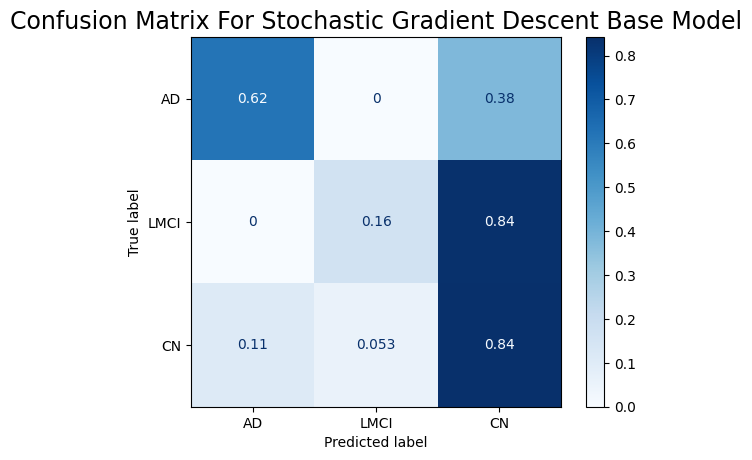

__________________________________________________________________


In [160]:
evaluate_model(sgd_base, X_train_balanced, X_test_balanced, y_test_balanced, title='Stochastic Gradient Descent Base Model')

/Users/keven/miniforge3/envs/final/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:723: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Best Parameters:  {'alpha': 0.1, 'eta0': 0.1, 'learning_rate': 'adaptive', 'loss': 'modified_huber', 'penalty': 'elasticnet'}
Best Estimator:  SGDClassifier(alpha=0.1, class_weight='balanced', eta0=0.1,
              learning_rate='adaptive', loss='modified_huber', n_jobs=-1,
              penalty='elasticnet', random_state=123)
__________________________________________________________________
CLASSIFICATION REPORT FOR: 
	Tuned Stochastic Gradient Descent Model
__________________________________________________________________


              precision    recall  f1-score   support

          AD       0.75      0.90      0.82        71
        LMCI       0.73      0.60      0.66        55
          CN       0.51      0.47      0.49        57

    accuracy                           0.68       183
   macro avg       0.67      0.66      0.66       183
weighted avg       0.67      0.68      0.67       183

__________________________________________________________________


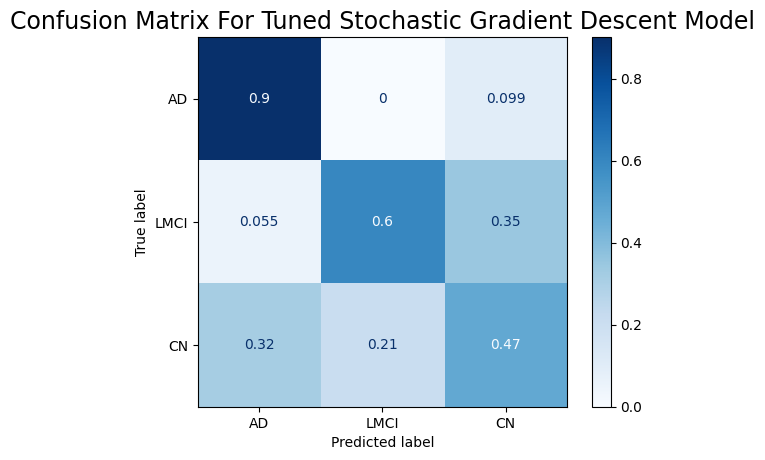

__________________________________________________________________


In [161]:

# Define the parameter grid
param_grid = {
    'loss': ['hinge', 'log', 'modified_huber', 'squared_hinge', 'perceptron'],
    'penalty': ['l2', 'l1', 'elasticnet'],
    'alpha': [0.0001, 0.001, 0.01, 0.1],
    'learning_rate': ['constant', 'optimal', 'invscaling', 'adaptive'],
    'eta0': [0.01, 0.1, 1]
}

# Perform grid search
grid_search = GridSearchCV(estimator=sgd_clf, param_grid=param_grid, scoring='accuracy', n_jobs=-1, cv=5)
grid_search.fit(X_train_balanced, y_train_balanced)

# Best parameters and estimator
best_params = grid_search.best_params_
best_estimator = grid_search.best_estimator_

print("Best Parameters: ", best_params)
print("Best Estimator: ", best_estimator)

# Evaluate the tuned model
evaluate_model(best_estimator, X_train_balanced, X_test_balanced, y_test_balanced, title='Tuned Stochastic Gradient Descent Model')


In [164]:
log_clf_preds = log_clf.predict(X_test_balanced)
    
log_clf_accuracy = (log_clf_preds == y_test_balanced)
print('Test Accuracy =', format( np.sum(log_clf_accuracy)/num_test, '.2%'))

Test Accuracy = 71.58%


In [165]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

log_clf = LogisticRegressionCV(solver='lbfgs', penalty='l2', max_iter=1000000, multi_class='multinomial')
log_clf.fit(X_train_balanced, y_train_balanced)
log_clf_preds = log_clf.predict(X_test_balanced)

print('Logistic Regression:')
print('Accuracy:', format(accuracy_score(y_test_balanced, log_clf_preds), '.2%'))
print('Precision:', format(precision_score(y_test_balanced, log_clf_preds, average='weighted'), '.2%'))
print('Recall:', format(recall_score(y_test_balanced, log_clf_preds, average='weighted'), '.2%'))
print('F1 Score:', format(f1_score(y_test_balanced, log_clf_preds, average='weighted'), '.2%'))

Logistic Regression:
Accuracy: 71.58%
Precision: 73.97%
Recall: 71.58%
F1 Score: 72.38%


In [168]:
joblib.dump(log_clf, './models/alzheimer_info_model.pkl')

['./models/alzheimer_info_model.pkl']